# Métodos de la revisión de literatura

Explicaciones **conceptuales** de los métodos que aparecen en los artículos de mi revisión de literatura. El objetivo es tener claro el concepto de cada método, no un tratamiento exhaustivo.

Los métodos están organizados **por función**: cada función es una sección de nivel 1 y cada método una subsección dentro de ella. Cada método se explica como una narrativa corta: para qué sirve → idea central (fórmula y gráfica) → requisitos o limitación principal → aplicación a puentes → tabla de fortalezas y debilidades. El texto está en español; el código, en inglés.

## Tabla de contenido

| Función | Método |
|---|---|
| [1. Envolvente de amplitud / amplitud instantánea](#envolvente-de-amplitud) | [1.1 Transformada de Hilbert](#transformada-de-hilbert) |

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import hilbert, butter, sosfiltfilt

# Shared plot style: thin lines, recessive grid, no top/right spines
plt.rcParams.update({
    "figure.dpi": 110,
    "axes.grid": True,
    "grid.color": "#e3e2de",
    "grid.linewidth": 0.6,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.edgecolor": "#8a8984",
    "axes.labelcolor": "#2b2b2a",
    "xtick.color": "#52514e",
    "ytick.color": "#52514e",
    "lines.linewidth": 1.4,
    "legend.frameon": False,
})

# Fixed color roles (same meaning in every plot)
COLOR_SIGNAL = "#8a8984"   # raw / measured signal (neutral gray)
COLOR_1 = "#2a78d6"        # main series (blue)
COLOR_2 = "#eb6834"        # second series (orange)
COLOR_TRUE = "#0b0b0b"     # exact (true) reference curve, dashed

<a id="envolvente-de-amplitud"></a>
# 1. Envolvente de amplitud / amplitud instantánea

Métodos que calculan, en cada instante, la amplitud de una oscilación (su envolvente), sin las subidas y bajadas propias de cada ciclo.

<a id="transformada-de-hilbert"></a>
## 1.1 Transformada de Hilbert

### Para qué sirve

La transformada de Hilbert da la **amplitud de una vibración en cada instante** (la envolvente). La FFT no lo hace, porque promedia todo el registro: dice qué frecuencias hay, pero no cómo cambia su amplitud en el tiempo. En puentes interesa porque, cuando un vehículo cruza, la amplitud del modo cambia con la posición del vehículo, y esa variación refleja la **forma modal**.

### La idea: copia desfasada 90° y envolvente

La transformada genera una **copia de la señal desfasada 90°**, $\mathcal{H}[x(t)]$. Donde una de las dos pasa por cero, la otra está en su máximo, así que juntas siempre "ven" la amplitud. Combinándolas sale la envolvente:

$$
A(t) = \sqrt{x(t)^2 + \mathcal{H}[x(t)]^2}
$$

- $A(t)$: amplitud instantánea o envolvente.
- $x(t)$: señal medida.
- $\mathcal{H}[x(t)]$: transformada de Hilbert, la señal desfasada 90°.

En palabras: la raíz de la señal al cuadrado más su versión desfasada al cuadrado. Por ejemplo, para $x = a\cos(\omega t)$ la copia es $a\sin(\omega t)$ y $A = \sqrt{a^2\cos^2 + a^2\sin^2} = a$.

Ejemplo: un vehículo cruza un puente de $L = 15$ m a $v = 2$ m/s; la componente del modo 1 ($f_1 = 5.65$ Hz) es $x(t) = \sin(\pi v t / L)\cos(2\pi f_1 t)$, muestreada a $f_s = 200$ Hz.

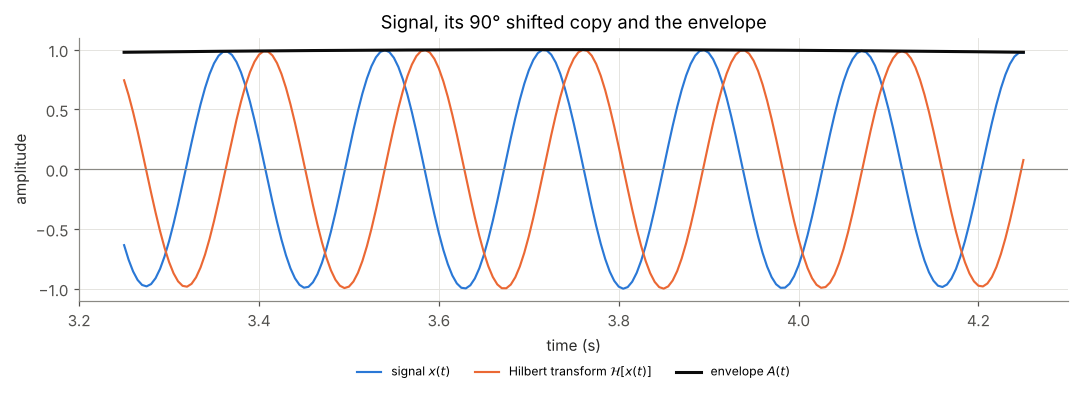

In [2]:
# --- Example: vehicle crossing a simply supported bridge ---
L_SPAN = 15.0         # span (m)
V_SPEED = 2.0         # vehicle speed (m/s)
F1, F2 = 5.65, 22.62  # bridge natural frequencies (Hz)
FS = 200.0            # sampling frequency (Hz)

t = np.arange(0, L_SPAN / V_SPEED, 1 / FS)
position = V_SPEED * t                      # vehicle position x = v t (m)
phi_1 = np.sin(np.pi * position / L_SPAN)   # mode 1 shape
phi_2 = np.sin(2 * np.pi * position / L_SPAN)  # mode 2 shape

x_ideal = phi_1 * np.cos(2 * np.pi * F1 * t)

z = hilbert(x_ideal)              # analytic signal x + j H[x]
hilbert_x = np.imag(z)            # H[x(t)], the 90° shifted copy
envelope_ideal = np.abs(z)        # A(t) = sqrt(x^2 + H[x]^2)

window = (t >= 3.25) & (t <= 4.25)  # zoom into ~1 s around midspan
fig, ax = plt.subplots(figsize=(10, 3.8))
ax.plot(t[window], x_ideal[window], color=COLOR_1, label="signal $x(t)$")
ax.plot(t[window], hilbert_x[window], color=COLOR_2, label=r"Hilbert transform $\mathcal{H}[x(t)]$")
ax.plot(t[window], envelope_ideal[window], color=COLOR_TRUE, linewidth=2, label="envelope $A(t)$")
ax.axhline(0, color=COLOR_SIGNAL, linewidth=0.8)
ax.set_xlabel("time (s)")
ax.set_ylabel("amplitude")
ax.set_title("Signal, its 90° shifted copy and the envelope")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.2), ncol=3, fontsize=8)
fig.tight_layout()
plt.show()

**Interpretación.** Donde la señal azul cruza el cero, la naranja está en un pico, y viceversa. La envolvente (negra) pasa por encima de ambas sin oscilar: es la amplitud en cada instante.

### Requisito: una sola componente

No hace falta una senoidal pura: la amplitud puede variar, siempre que cambie mucho más lento que la oscilación. Pero la señal debe tener **una sola frecuencia dominante**. Si mezcla varias, la envolvente sale ondulada y no significa nada.

Por eso, antes de aplicar Hilbert:

- se **quita la media** de la señal;
- se **aísla la componente**: con un **filtro pasabanda** (si se conoce la frecuencia) o con una descomposición como la **EMD** (EMD + Hilbert = transformada de Hilbert-Huang, **HHT**).

Ejemplo: señal con el modo 1 (5.65 Hz), el modo 2 (22.62 Hz, forma $\sin(2\pi x/L)$, menor amplitud) y ruido.

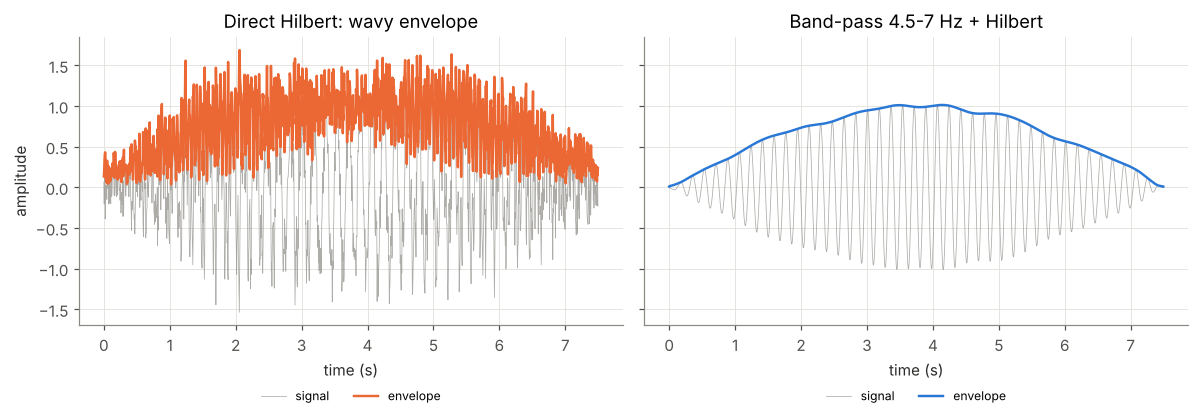

In [3]:
rng = np.random.default_rng(42)   # fixed seed for the noise

x_mode_2 = 0.5 * phi_2 * np.cos(2 * np.pi * F2 * t)
noise = 0.2 * rng.standard_normal(t.size)
x_measured = x_ideal + x_mode_2 + noise
x_measured = x_measured - x_measured.mean()   # remove the mean

# (a) Hilbert applied directly
envelope_direct = np.abs(hilbert(x_measured))

# (b) Band-pass 4.5-7 Hz (4th-order Butterworth, zero phase), then Hilbert
sos = butter(4, [4.5, 7.0], btype="band", fs=FS, output="sos")
x_filtered = sosfiltfilt(sos, x_measured)
envelope_filtered = np.abs(hilbert(x_filtered))

fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for ax, x, env, color, title in [
    (axes[0], x_measured, envelope_direct, COLOR_2, "Direct Hilbert: wavy envelope"),
    (axes[1], x_filtered, envelope_filtered, COLOR_1, "Band-pass 4.5-7 Hz + Hilbert"),
]:
    ax.plot(t, x, color=COLOR_SIGNAL, linewidth=0.5, alpha=0.7, label="signal")
    ax.plot(t, env, color=color, linewidth=1.6, label="envelope")
    ax.set_title(title)
    ax.set_xlabel("time (s)")
    ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.18), ncol=2, fontsize=8)
axes[0].set_ylabel("amplitude")
fig.tight_layout()
plt.show()

**Interpretación.** Aplicada directo, la envolvente sube y baja rápido: el modo 2 y el ruido se suman y se restan con el modo 1, y la curva no representa nada físico. Después del pasabanda queda solo el modo 1 y la envolvente es suave.

### Aplicación a puentes

Al graficar la envolvente contra la **posición del vehículo** ($x = vt$) se obtiene la forma del modo. Dos puntos a tener en cuenta:

- La envolvente es el **valor absoluto**, sin signo: en el segundo modo, que es positivo en una mitad del vano y negativo en la otra, daría $|\phi_2|$ y no se distingue qué lado sube y cuál baja.
- Los **extremos se distorsionan** (efecto de borde), por lo que los primeros y últimos ciclos no se interpretan.

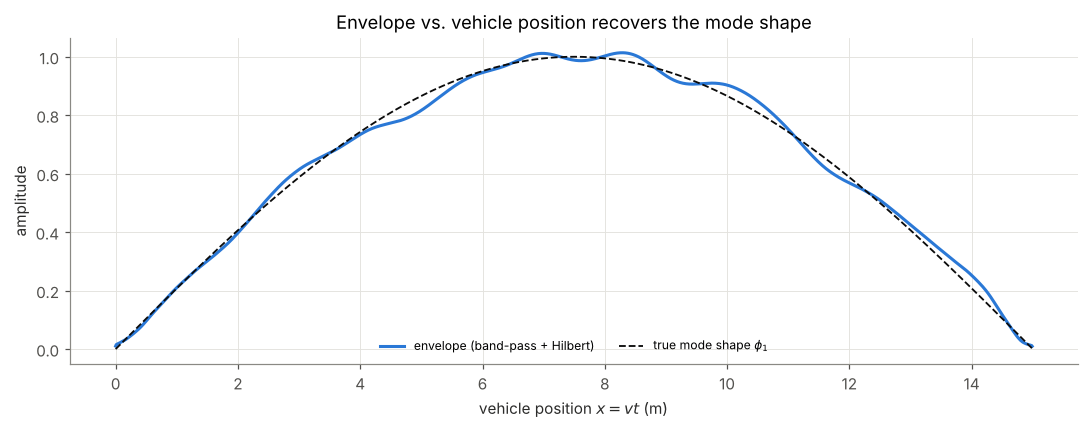

In [4]:
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(position, envelope_filtered, color=COLOR_1, linewidth=2, label="envelope (band-pass + Hilbert)")
ax.plot(position, phi_1, "--", color=COLOR_TRUE, linewidth=1.2, label=r"true mode shape $\phi_1$")
ax.set_xlabel("vehicle position $x = vt$ (m)")
ax.set_ylabel("amplitude")
ax.set_title("Envelope vs. vehicle position recovers the mode shape")
ax.legend(loc="lower center", ncol=2, fontsize=8)
fig.tight_layout()
plt.show()

**Interpretación.** La envolvente sigue la forma modal real; las pequeñas ondulaciones vienen del ruido que cae dentro de la banda del filtro. En este ejemplo los extremos casi no se distorsionan porque la señal empieza y termina con amplitud cero; con señales reales, que no empiezan ni terminan en cero, el efecto de borde sí se nota.

**En la literatura:** Malekjafarian y OBrien (2017) la usan así: aplican la HHT a las aceleraciones de los ejes de un camión con remolques que lleva un excitador, para estimar las formas modales del puente. Su validación es solo en simulación.

### Resumen

| Fortalezas | Debilidades |
|---|---|
| Da la amplitud en cada instante | Exige una sola componente (filtrado o descomposición previa) |
| Sirve para señales que cambian en el tiempo | Sensible al ruido |
| Simple y rápida | Efectos de borde |
| | Pierde el signo de la forma modal |